# 17 — El clima completo: sol, nubes, rachas y cambios bruscos

## Qué pidió el propietario

Que el modelo no se quede con «temperatura y si llovió». Quiere el **contexto completo**: humedad,
precipitación, sol, **cuánto tiempo lleva haciendo sol**, los **cambios bruscos**. Es lo que `CLAUDE.md` llama
«importa la transición, no el nivel», y que hasta hoy **no existía como variable**.

## Qué se hizo (fila `clima_completo` de `variables.csv`, fijada antes de mirar)

- **Datos nuevos:** `calendarios/clima/clima_completo.py`, en el mismo punto que el clima actual (La Nubia),
  **desde 2010**.
  - Horas de sol, nubosidad, punto de rocío, déficit de presión de vapor, humedad, temperatura y radiación
    salen de Open-Meteo/ERA5.
  - La lluvia sale de NASA POWER.
- **Variables:**
  - cada nivel como anomalía contra lo normal del mes, en 7 y 28 días;
  - cada **cambio** (la última semana contra las tres anteriores);
  - las **rachas** (días en racha seca, días seguidos de sol, días desde la última semana muy lluviosa);
  - los **extremos** (noches frías);
  - la **transición de seco a lluvioso**.
- **Exploración**, contra tres desenlaces y **solo con 2010-2024**:
  1. **la IRA de Manizales** (SIVIGILA 995, 2012-2024, sin la COVID): es donde el clima debería verse;
  2. **los ingresos respiratorios del hospital** (2021-2024);
  3. **el triage total** sin calendario ni escalones de la red (2022-2024).
- **Método:** rezagos de 0 a 6 semanas, con mes y año fijos (la estación no cuenta como efecto), errores HAC,
  y Benjamini-Hochberg con q = 0,10 por desenlace.
- **2025 y 2026 no se miran aquí:** están reservados para elegir y probar el modelo.

**Antes de usar los datos se validaron**, porque toda fuente puede estar rota:
- **la lluvia del ERA5 en Manizales da ~16.000 mm al año**, 10 veces lo real, con correlación −0,02 frente
  al pluviómetro. **Se descartó.**
- La lluvia de NASA da ~2.060 mm al año, y frente al pluviómetro correlaciona 0,30 por día, 0,52 por semana
  y 0,80 por mes. Por eso **toda variable de lluvia usa ventanas de 7 días o más**.

In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "notebooks")); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from matplotlib import pyplot as plt
from desenlace import desenlace_semanal

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
FIN_EXPLORA = "2024-12-31"
cc = pd.read_csv(RAIZ / "calendarios/clima_completo.csv.gz", index_col=0, parse_dates=True)
def semana(s, como="mean"):
    r = getattr(s.resample("W-SAT"), como)(); r.index = r.index - pd.Timedelta(days=6); return r
NIVELES = ["temp", "tmin", "tmax", "lluvia", "sol", "nubes", "rocio", "humedad", "vpd", "radiacion", "viento"]
F = {}
for n in NIVELES:
    F[f"{n}_7d"] = semana(cc[f"{n}_7d"]); F[f"{n}_28d"] = semana(cc[f"{n}_28d"]); F[f"{n}_cambio"] = semana(cc[f"{n}_cambio"])
F["dias_en_racha_seca"] = semana(cc.dias_en_racha_seca, "max"); F["dias_de_sol"] = semana(cc.dias_de_sol, "max")
F["dias_desde_semana_muy_lluviosa"] = semana(cc.dias_desde_semana_muy_lluviosa, "min")
F["extremos_frio_7d"] = semana(cc.extremos_frio_7d, "max"); F["seco_a_lluvioso"] = semana(cc.seco_a_lluvioso, "max")
F = pd.DataFrame(F)
FAMILIA = {c: ("nivel 7 días" if c.endswith("_7d") and c.split("_")[0] in NIVELES else "nivel 28 días" if c.endswith("_28d") else
               "cambio brusco" if c.endswith("_cambio") else "racha / extremo / transición") for c in F}
print(f"{F.shape[1]} variables semanales de clima, {F.index[0].date()} a {F.index[-1].date()}")
pd.Series(FAMILIA).value_counts()

38 variables semanales de clima, 2009-12-27 a 2026-09-27


nivel 7 días                    11
nivel 28 días                   11
cambio brusco                   11
racha / extremo / transición     5
Name: count, dtype: int64

---
# 1. Cómo se ve el clima nuevo

Las variables que no existían: horas de sol, nubosidad, rachas y la transición de seco a lluvioso.

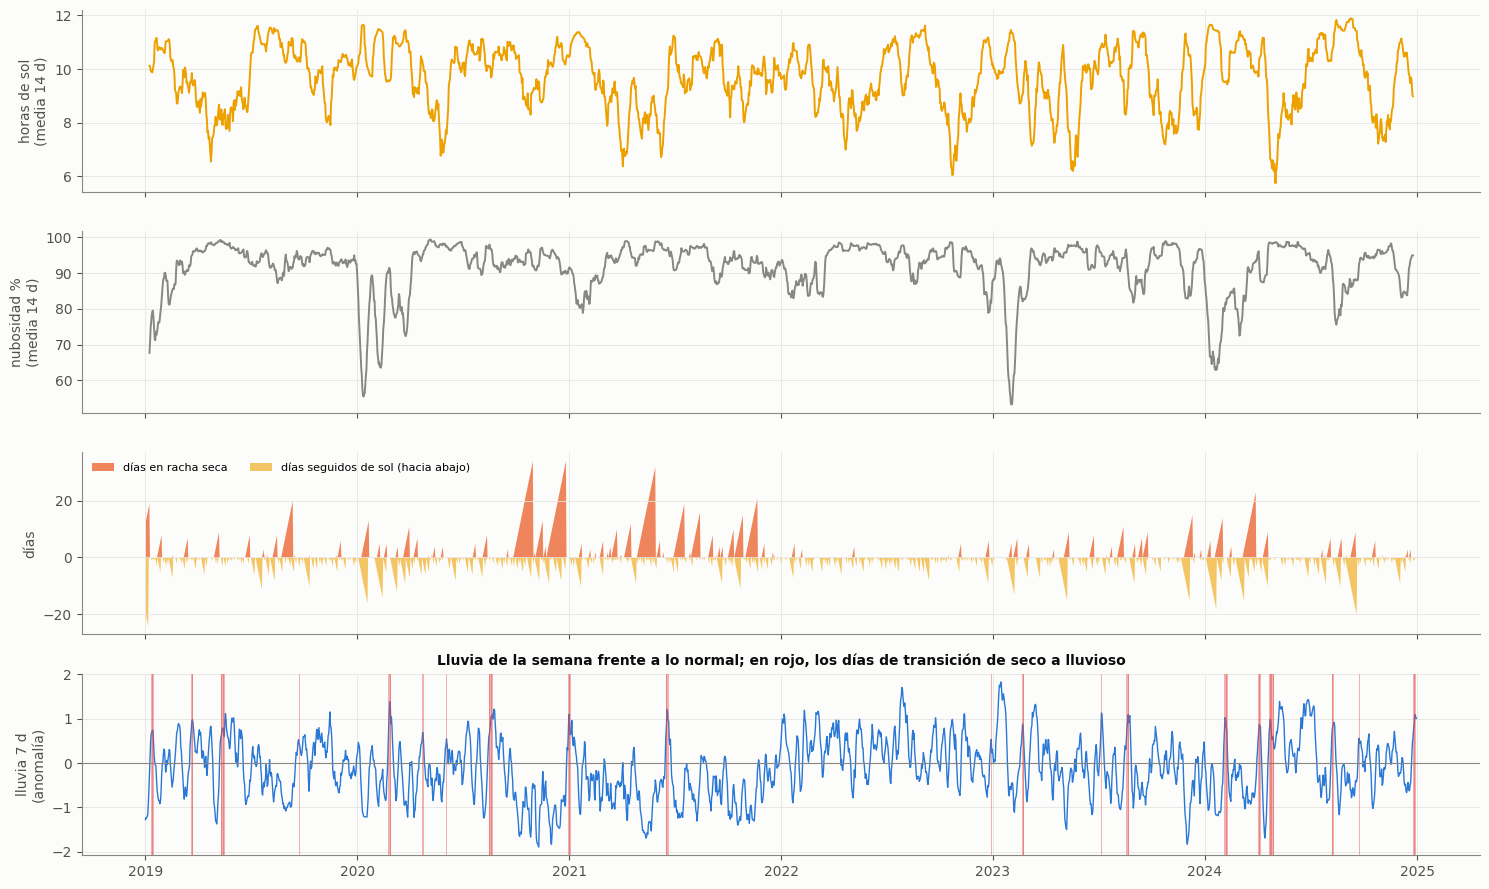

Días de transición seco → lluvioso por año: {2010: 4, 2011: 4, 2012: 4, 2013: 0, 2014: 1, 2015: 6, 2016: 7, 2017: 11, 2018: 10, 2019: 14, 2020: 15, 2021: 6, 2022: 1, 2023: 8, 2024: 25}


In [2]:
v = cc.loc["2019-01-01":FIN_EXPLORA]
fig, axes = plt.subplots(4, 1, figsize=(15, 9), sharex=True)
axes[0].plot(v.index, v.horas_sol.rolling(14, center=True).mean(), color=AMARILLO, lw=1.4); axes[0].set_ylabel("horas de sol\n(media 14 d)")
axes[1].plot(v.index, v.cloud_cover_mean.rolling(14, center=True).mean(), color=MUDO, lw=1.4); axes[1].set_ylabel("nubosidad %\n(media 14 d)")
axes[2].fill_between(v.index, 0, v.dias_en_racha_seca, color=NARANJA, lw=0, alpha=.8, label="días en racha seca")
axes[2].fill_between(v.index, 0, -v.dias_de_sol.clip(upper=30), color=AMARILLO, lw=0, alpha=.6, label="días seguidos de sol (hacia abajo)")
axes[2].legend(loc="upper left", fontsize=8, ncol=2); axes[2].set_ylabel("días")
axes[3].plot(v.index, v.lluvia_7d, color=AZUL, lw=1); axes[3].axhline(0, color=MUDO, lw=.8)
for d in v.index[v.seco_a_lluvioso > 0]: axes[3].axvline(d, color=ROJO, lw=.6, alpha=.5)
axes[3].set_ylabel("lluvia 7 d\n(anomalía)"); axes[3].set_title("Lluvia de la semana frente a lo normal; en rojo, los días de transición de seco a lluvioso", fontsize=10)
plt.tight_layout(); plt.show()
print("Días de transición seco → lluvioso por año:", cc.seco_a_lluvioso.groupby(cc.index.year).sum().astype(int).loc[:2024].to_dict())

**Lectura.**

- **Las horas de sol y la nubosidad tienen la estación de Manizales:** más sol en enero-febrero y en julio-agosto, más nubes en abril-mayo y octubre-noviembre.
- **Las rachas secas largas coinciden con El Niño.** 2015-16 y 2023-24 tienen rachas de 20 a 37 días con la lluvia de la semana por debajo de lo normal.
- **La transición de seco a lluvioso es rara:** de 0 a 25 días al año. **2024 tiene 25**, justo al terminar El Niño 2023-24. Ese tipo de giro es el que `CLAUDE.md` pone como ejemplo.

---
# 2. Los desenlaces

In [3]:
v = pd.read_csv(RAIZ / "calendarios/vigilancia_sivigila.csv.gz", parse_dates=["fecha_inicio_semana"])
ira = (v[(v.ambito == "manizales") & (v.evento == 995) & (v.variable == "consultas_ira_total")]
         .drop_duplicates("fecha_inicio_semana").set_index("fecha_inicio_semana").valor.astype(float))
ira = np.log(ira.loc["2012-01-01":FIN_EXPLORA]); ira[(ira.index >= "2020-03-15") & (ira.index <= "2021-12-31")] = np.nan
dx = pd.read_parquet(RAIZ / "salidas/perfil_dx_diario.parquet"); dx["dia"] = pd.to_datetime(dx.dia)
resp = dx[dx.capitulo == "X Respiratorio"].set_index("dia").n.reindex(pd.date_range("2020-01-01", FIN_EXPLORA)).fillna(0)
resp = np.log1p(semana(resp, "sum")).loc["2021-01-01":FIN_EXPLORA]
tot = desenlace_semanal().y.loc[:FIN_EXPLORA]
DES = {"IRA de Manizales": ira, "ingresos respiratorios del hospital": resp, "triage total (sin calendario ni red)": tot}
for k, s in DES.items(): print(f"{k}: {s.notna().sum()} semanas, {s.dropna().index[0].date()} a {s.dropna().index[-1].date()}")

IRA de Manizales: 585 semanas, 2012-01-01 a 2024-12-29
ingresos respiratorios del hospital: 209 semanas, 2021-01-03 a 2024-12-29
triage total (sin calendario ni red): 147 semanas, 2022-03-06 a 2024-12-29


---
# 3. El barrido: cada variable de clima, con rezago de 0 a 6 semanas

Por cada desenlace, variable y rezago: `desenlace(semana t) ~ clima(semana t − rezago) + mes + año`. El
efecto se lee como **% de cambio en el desenlace por cada desviación típica de la variable**, con errores HAC.

In [4]:
def barrido(y, X, rezagos=range(0, 7)):
    filas = []
    idx = y.dropna().index
    mes = pd.get_dummies(pd.Index(idx.month), prefix="m", drop_first=True).set_index(idx).astype(float)
    anio = pd.get_dummies(pd.Index(idx.year), prefix="a", drop_first=True).set_index(idx).astype(float)
    for c in X:
        xs = (X[c] - X[c].loc[:FIN_EXPLORA].mean()) / X[c].loc[:FIN_EXPLORA].std()
        for L in rezagos:
            D = pd.concat([y.rename("y"), xs.shift(L).rename("x"), mes, anio], axis=1).loc[idx].dropna()
            if len(D) < 60 or D.x.std() == 0: continue
            r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
            filas.append({"variable": c, "familia": FAMILIA[c], "rezago": L, "efecto %": 100 * (np.exp(r.params["x"]) - 1), "p": r.pvalues["x"], "n": len(D)})
    T = pd.DataFrame(filas); T["q"] = multipletests(T.p, method="fdr_bh")[1]
    return T
RES = {k: barrido(s, F) for k, s in DES.items()}
resumen = pd.DataFrame({k: {"pruebas": len(T), "p < 0,05": int((T.p < .05).sum()), "azar esperaría": round(.05 * len(T)),
                            "sobreviven BH (q < 0,10)": int((T.q < .10).sum())} for k, T in RES.items()}).T
resumen

,pruebas,"p < 0,05",azar esperaría,"sobreviven BH (q < 0,10)"
IRA de Manizales,266,72,13,53
ingresos respiratorios del hospital,266,5,13,0
triage total (sin calendario ni red),266,63,13,36


**Lectura.** Tres desenlaces, tres respuestas muy distintas:

1. **La IRA de la ciudad responde al clima, y mucho:** 72 pruebas con p < 0,05, cuando el azar daría 13, y **53 sobreviven a BH**. Con 13 años de datos (585 semanas), la señal es robusta.
2. **El triage total también responde, pero poco:** 36 sobreviven, con efectos de 1,5 a 2,4 % por desviación típica. Es la **dilución** que anticipaba `CLAUDE.md`: el clima mueve lo respiratorio, que es una fracción del total.
3. **Los ingresos respiratorios del hospital no responden:** 5 pruebas con p < 0,05, que es menos de lo que daría el azar, y 0 sobreviven.
   - Son **ingresos**: los pacientes que el hospital se queda, un tercio de los que llegan (cuaderno 10), y unos 33 por semana.
   - Para ver el efecto en el hospital hace falta el **triage** respiratorio, que existe en el texto de las notas (fase NLP), o un conteo por diagnóstico de urgencias.

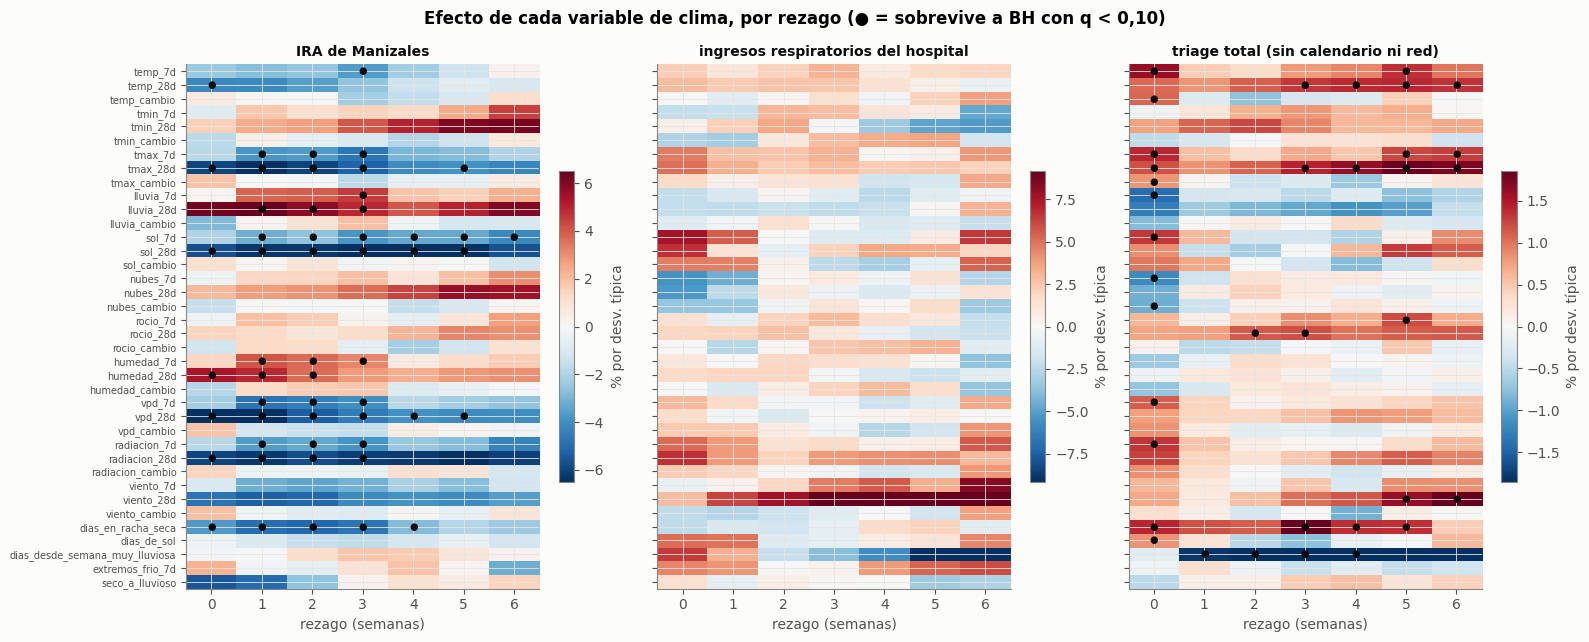

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6.5), sharey=True)
orden = list(F.columns)
for ax, (k, T) in zip(axes, RES.items()):
    M = T.pivot_table(index="variable", columns="rezago", values="efecto %").reindex(orden)
    Q = T.pivot_table(index="variable", columns="rezago", values="q").reindex(orden)
    lim = np.nanpercentile(np.abs(M.values), 98)
    im = ax.imshow(M.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    for (i, j), q in np.ndenumerate(Q.values):
        if q < .10: ax.text(j, i, "●", ha="center", va="center", fontsize=7, color=TINTA)
    ax.set_xticks(range(M.shape[1]), M.columns); ax.set_xlabel("rezago (semanas)"); ax.set_title(k, fontsize=10)
    plt.colorbar(im, ax=ax, fraction=.04, label="% por desv. típica")
axes[0].set_yticks(range(len(orden)), orden, fontsize=7)
fig.suptitle("Efecto de cada variable de clima, por rezago (● = sobrevive a BH con q < 0,10)", fontweight="bold"); plt.tight_layout(); plt.show()

In [6]:
top = []
for k, T in RES.items():
    t = T[T.q < .10].copy(); t["desenlace"] = k; top.append(t)
TOP = pd.concat(top) if top else pd.DataFrame()
print("Lo que sobrevive a BH, ordenado por tamaño del efecto dentro de cada desenlace:")
(TOP.assign(abs_=TOP["efecto %"].abs()).sort_values(["desenlace", "abs_"], ascending=[True, False])
    .groupby("desenlace").head(12)[["desenlace", "variable", "familia", "rezago", "efecto %", "q", "n"]].round(3)) if len(TOP) else "nada sobrevive"

Lo que sobrevive a BH, ordenado por tamaño del efecto dentro de cada desenlace:


,desenlace,variable,familia,rezago,efecto %,q,n
71,IRA de Manizales,lluvia_28d,nivel 28 días,1,7.049,0.088,585
94,IRA de Manizales,sol_28d,nivel 28 días,3,-6.976,0.013,585
95,IRA de Manizales,sol_28d,nivel 28 días,4,-6.864,0.023,585
175,IRA de Manizales,vpd_28d,nivel 28 días,0,-6.676,0.002,585
176,IRA de Manizales,vpd_28d,nivel 28 días,1,-6.512,0.002,585
50,IRA de Manizales,tmax_28d,nivel 28 días,1,-6.484,0.013,585
96,IRA de Manizales,sol_28d,nivel 28 días,5,-6.428,0.053,585
92,IRA de Manizales,sol_28d,nivel 28 días,1,-6.333,0.009,585
197,IRA de Manizales,radiacion_28d,nivel 28 días,1,-6.275,0.013,585
93,IRA de Manizales,sol_28d,nivel 28 días,2,-6.262,0.009,585


**Lectura.**

- **Para la IRA de la ciudad, el patrón es coherente:** un **mes** (28 días) **lluvioso, nublado, húmedo y con poco sol** trae **6-7 % más IRA** de 1 a 5 semanas después, por cada desviación típica:
  - lluvia de 28 días, +7,0 % a 1 semana;
  - horas de sol, −7,0 % a 3 semanas;
  - déficit de presión de vapor (aire seco), −6,7 %;
  - temperatura máxima, −6,5 %;
  - radiación, −6,3 %.

  Es el «frío y humedad del último mes» del cuaderno 11, ahora con **horas de sol y sequedad del aire** como piezas nuevas que lo confirman desde otra variable.
- **Para el triage total los efectos son pequeños:**
  - **una semana muy lluviosa reciente** sube el triage: cuantos más días desde la última, −2,4 % a 2-4 semanas;
  - **una racha seca larga** lo sube +2,1 % a 3 semanas;
  - el calor del último mes, +1,6 a +1,8 % a 4-6 semanas.
- **La escala temporal manda.** Lo que pesa es el **mes** (28 días), no la semana. Es coherente con un mecanismo de contagio y con el rezago de días a semanas que pide `CLAUDE.md`.

---
# 4. ¿Aportan las variables NUEVAS?

Se separan las que ya existían en el modelo (temperatura, humedad, lluvia, radiación y viento en nivel) de las
que se crearon ahora: horas de sol, nubosidad, punto de rocío, déficit de presión de vapor, los cambios
bruscos, las rachas, los extremos y la transición.

In [7]:
NUEVAS = lambda c: (c.split("_")[0] in ["sol", "nubes", "rocio", "vpd"]) or c.endswith("_cambio") or FAMILIA[c] == "racha / extremo / transición"
filas = []
for k, T in RES.items():
    for grupo, sel in [("ya existían (niveles)", ~T.variable.map(NUEVAS)), ("nuevas", T.variable.map(NUEVAS))]:
        t = T[sel]; filas.append({"desenlace": k, "grupo": grupo, "pruebas": len(t), "sobreviven BH": int((t.q < .10).sum()),
                                  "% que sobrevive": round(100 * (t.q < .10).mean(), 1), "mayor efecto %": round(t.loc[t.q < .10, "efecto %"].abs().max(), 1) if (t.q < .10).any() else np.nan})
pd.DataFrame(filas).set_index(["desenlace", "grupo"])

pruebas  \
desenlace                            grupo                            
IRA de Manizales                     ya existían (niveles)       98   
                                     nuevas                     168   
ingresos respiratorios del hospital  ya existían (niveles)       98   
                                     nuevas                     168   
triage total (sin calendario ni red) ya existían (niveles)       98   
                                     nuevas                     168   

                                                            sobreviven BH  \
desenlace                            grupo                                  
IRA de Manizales                     ya existían (niveles)             27   
                                     nuevas                            26   
ingresos respiratorios del hospital  ya existían (niveles)              0   
                                     nuevas                             0   
triage total (sin calendario ni red) ya existían (niveles)             18   
                                     nuevas                            18   

                                                            % que sobrevive  \
desenlace                            grupo                                    
IRA de Manizales                     ya existían (niveles)             27.6   
                                     nuevas                            15.5   
ingresos respiratorios del hospital  ya existían (niveles)              0.0   
                                     nuevas                             0.0   
triage total (sin calendario ni red) ya existían (niveles)             18.4   
                                     nuevas                            10.7   

                                                            mayor efecto %  
desenlace                            grupo                                  
IRA de Manizales                     ya existían (niveles)             7.0  
                                     nuevas                            7.0  
ingresos respiratorios del hospital  ya existían (niveles)             NaN  
                                     nuevas                            NaN  
triage total (sin calendario ni red) ya existían (niveles)             1.8  
                                     nuevas                            2.4

**Lectura.**

- **Las variables nuevas aportan, pero no reemplazan a las de siempre.** En la IRA sobreviven 26 de 168 nuevas y 27 de 98 que ya existían, y entre las nuevas están dos de las más fuertes: **horas de sol y déficit de presión de vapor**.
- **Lo nuevo que más rinde son los niveles de 28 días de sol y sequedad del aire.** Los cambios bruscos, las rachas y la transición sobreviven menos.
- **La transición de seco a lluvioso no aparece fuerte.** Con 0-25 días al año es un evento raro, y con 13 años de datos tiene pocos ejemplos: el mismo límite de muestra del cuaderno 16. Queda como variable, no como hallazgo.
- **En el triage total**, las rachas (días desde una semana muy lluviosa, días en racha seca) están entre lo poco que sobrevive.

---
# 5. Índices: resumir el clima en pocas cifras

Para no darle al modelo 40 variables sueltas, que en el cuaderno 15 lo sobreajustaron, se resumen en
**componentes principales**, ajustados solo con 2010-2024:
- el **«estado del clima»**: los niveles de 7 días;
- el **«cambio brusco»**: los cambios.

In [8]:
from sklearn.decomposition import PCA
def indices(cols, k, nombre):
    Z = F[cols].loc["2010-01-10":FIN_EXPLORA].dropna(); mu, sd = Z.mean(), Z.std()
    p = PCA(k).fit((Z - mu) / sd)
    S = pd.DataFrame(p.transform(((F[cols] - mu) / sd).dropna()), index=F[cols].dropna().index, columns=[f"{nombre}_{i + 1}" for i in range(k)])
    L = pd.DataFrame(p.components_.T, index=cols, columns=S.columns).round(2)
    return S, L, p.explained_variance_ratio_
S1, L1, v1 = indices([f"{n}_7d" for n in NIVELES], 4, "estado")
S2, L2, v2 = indices([f"{n}_cambio" for n in NIVELES], 3, "cambio")
print(f"Estado del clima: 4 componentes explican {v1.sum():.0%} ({np.round(v1, 2)}); cambio brusco: 3 explican {v2.sum():.0%} ({np.round(v2, 2)})")
display(pd.concat([L1, L2], axis=1).fillna(""))
IDX = S1.join(S2, how="outer")
FAMILIA.update({c: "índice" for c in IDX})
RI = {k: barrido(s, IDX) for k, s in DES.items()}
pd.concat({k: T[T.q < .10][["variable", "rezago", "efecto %", "q"]] for k, T in RI.items()}).round(3)

Estado del clima: 4 componentes explican 86% ([0.49 0.22 0.09 0.07]); cambio brusco: 3 explican 81% ([0.54 0.19 0.08])


,estado_1,estado_2,estado_3,estado_4,cambio_1,cambio_2,cambio_3
temp_7d,0.19,0.56,-0.05,-0.14,,,
tmin_7d,-0.18,0.47,-0.32,-0.14,,,
tmax_7d,0.33,0.35,0.09,0.06,,,
lluvia_7d,-0.29,-0.07,-0.34,-0.03,,,
sol_7d,0.32,-0.07,-0.32,0.61,,,
nubes_7d,-0.32,0.1,0.32,0.06,,,
rocio_7d,-0.16,0.56,0.08,0.29,,,
humedad_7d,-0.37,0.05,0.14,0.49,,,
vpd_7d,0.4,0.05,-0.08,-0.34,,,
radiacion_7d,0.39,-0.04,-0.11,0.38,,,


variable  rezago  efecto %      q
IRA de Manizales                     1   estado_1       1    -4.117  0.061
                                     2   estado_1       2    -3.841  0.034
                                     3   estado_1       3    -4.146  0.021
triage total (sin calendario ni red) 0   estado_1       0     1.276  0.026
                                     12  estado_2       5     1.440  0.026

**Lectura.**

- **El clima de Manizales cabe en pocas cifras.** Cuatro componentes resumen el 86 % de los once niveles semanales:
  - **estado_1**, «semana soleada, seca y de aire seco» frente a «semana nublada, húmeda y lluviosa»: 49 %;
  - **estado_2**, temperatura y punto de rocío: «semana cálida y bochornosa»;
  - **estado_3**, viento;
  - **estado_4**, sol con humedad.
- Tres componentes resumen el 81 % de los cambios bruscos.
- **Con un solo índice, estado_1, se recupera lo esencial:** −4 % de IRA por desviación típica a 1-3 semanas, y +1,3 % de triage total en la misma semana.
- **Esta es la forma de dar al modelo el clima completo sin sobreajustar:** 4 + 3 índices en lugar de 38 variables.

---
# 6. Lo que deja este cuaderno

**Lo que deja este cuaderno:**

1. **El clima completo ya existe como dato** (`calendarios/clima_completo.csv.gz`, 2010-2026): sol, nubes, punto de rocío, sequedad del aire, rachas, extremos y transición.
   - **La lluvia del ERA5 se descartó** por estar rota (10 veces lo real).
   - La de NASA solo se usa en ventanas de 7 días o más.
2. **El clima mueve con claridad la IRA de la ciudad:** un mes lluvioso, nublado y húmedo trae 6-7 % más IRA a 1-5 semanas. **Al triage total llega diluido**, con 1,5-2,4 %.
3. **Al modelo deben entrar índices, no variables sueltas:** 4 de estado del clima y 3 de cambio, más dos o tres rachas.
4. **La vía del clima al hospital pasa por la IRA de la ciudad.** Encaja con el diseño jerárquico del cuaderno 16: el clima predice la IRA, y la IRA predice la parte respiratoria del triage.

**Límites:**
- Todo esto es **exploración en 2010-2024**. Que sirva para predecir se decide con 2025 y se prueba en 2026 (cuaderno 22).
- Es **clima observado**. En operación hará falta el **pronóstico** (Open-Meteo Previous Runs, desde 2024).